
# Lab 8: Monte Carlo Markov Chain (MCMC)

In [13]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

**Exercise 1**:
 
* 1. Compute $\int_0^4 x^{1/2} dx$ and compare with an analytic result.


In [7]:
def MC(func,a,b,num_samples=1000):
    integral_sum = 0
    for _ in range(num_samples):
        x=random.uniform(a,b)
        integral_sum+=func(x)
    return (b-a)*(integral_sum/num_samples)

def f(x):
    return np.sqrt(x)

sol=MC(f,0,4,1000000)
print(f"Monte Carlo: {sol}")
print(f"Analítico: {16/3}")

Monte Carlo: 5.3347373426008105
Analítico: 5.333333333333333


* 2.  Compute the double integral of $x\,y^2$ over the box x ranging from $0$ to $2$ and $y$ ranging from $0$ to $1$. That is,

$$\int_{x=0}^{x=2} \int_{y=0}^{y=1} xy^2 dy dx$$

In [10]:
def MC2(func,x_a,x_b,y_a,y_b,num_samples=1000):
    integral_sum=0
    for _ in range(num_samples):
        x=random.uniform(x_a,x_b)
        y=random.uniform(y_a,y_b)
        integral_sum+=func(x,y)
    
    area=(x_b-x_a)*(y_b-y_a)
    int=area*(integral_sum/num_samples)
    return int

def f2(x,y):
    return x*(y**2)

sol2=MC2(f2,0,2,0,1,1000000)
print(f"Monte Carlo 2D: {sol2}")
print(f"Analítico: {2/3}")

Monte Carlo 2D: 0.6662290943296408
Analítico: 0.6666666666666666


**Exercise 2**:

Read about the Ising's model 1D, 2D and 3D.

## Modelo de Ising 2D

Como aplicación de la distribución canónica en `Física estadística` tenemos el **modelo de Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material (https://en.wikipedia.org/wiki/Ising_model).

Considere un sistema compuesto por $N$ átomos no interactuantes en un material 2D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación de este sistema con el método de **Metrópolis Monte Carlo** (ver notebook). Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema. *Considere interacción con los primeros vecinos*.

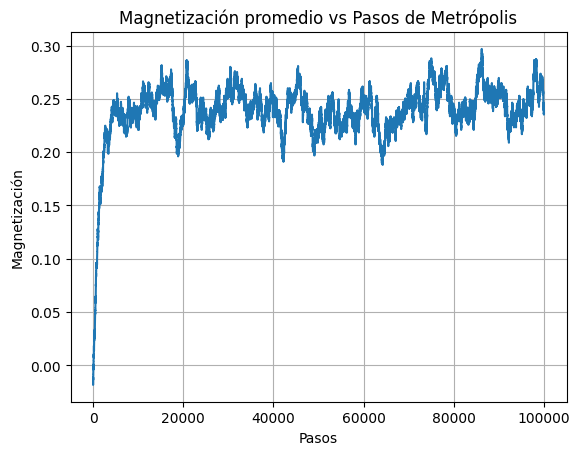

In [14]:
def metroIsing(N=50,steps=10000,T=2.0,mu=1.0,H=0.5):
    muestras=np.zeros(steps)

    red=np.random.choice([-1,1],size=(N,N))
    
    for i in range(steps):
        fila=np.random.randint(0,N)
        col=np.random.randint(0,N)
        espin_viejo=red[fila,col]
        
        espin_nuevo=-espin_viejo

        delta_E=2*mu*H*espin_viejo 
        aceptacion=np.exp(-delta_E/T)
        
        if aceptacion>=np.random.random():
            red[fila,col]=espin_nuevo
        else:
            red[fila,col]=espin_viejo 

        muestras[i]=np.sum(red)/(N*N)
        
    return red,muestras

N=50
pasos=100000
red_final,magnetizacion=metroIsing(N=N,steps=pasos,T=2.0)

plt.plot(magnetizacion)
plt.title('Magnetización promedio vs Pasos de Metrópolis')
plt.xlabel('Pasos')
plt.ylabel('Magnetización')
plt.grid()
plt.show()

2. Graficar la Magnetización media del material vs el campo magnetico para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,T < H < +30\,T$.  

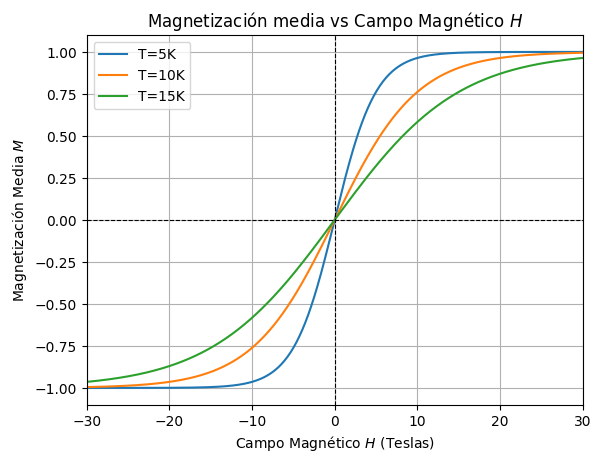

In [15]:
H=np.linspace(-30,30,500)
temperaturas=[5,10,15]

for T in temperaturas:
    M=np.tanh(H/T)
    plt.plot(H,M,label=f'T={T}K')

plt.title('Magnetización media vs Campo Magnético $H$')
plt.xlabel('Campo Magnético $H$ (Teslas)')
plt.ylabel('Magnetización Media $M$')

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')

plt.xlim(-30,30)
plt.ylim(-1.1,1.1)
plt.legend()
plt.grid()
plt.show()